# SwiftDrive — Clasificación del nivel de tráfico fluvial
**Inteligencia Artificial · Grupo T02 · Universidad Simón Bolívar**

Modelo supervisado (Árbol de Decisión) que clasifica si una operación portuaria tendrá tráfico **FLUVIAL ALTO (1)** o **BAJO (0)** según zona, sociedad portuaria, tipo de carga, año y mes.

Dataset: *Tráfico Portuario Marítimo en Colombia* — SUPERTRANSPORTE ([datos.gov.co](https://www.datos.gov.co/Transporte/Trafico-Portuario-Mar-timo-En-Colombia/5r3g-zv5z/about_data)).

> **Correcciones respecto a la versión anterior**
> 1. El CSV usa el punto como separador de miles (`1.389` = 1389, `2.023` = 2023). Se lee con `thousands='.'`.
> 2. La función de predicción ya no reemplaza en silencio valores que no existen: valida la entrada y muestra las opciones válidas.
> 3. Se corrigen nombres con caracteres dañados (`COMPA�IA` → `COMPAÑIA`).
> 4. La partición 80/20 es estratificada para conservar la proporción de clases.

## Sección 1: Importación de librerías

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("¡Librerías importadas correctamente!")

¡Librerías importadas correctamente!


## Sección 2: Carga del CSV e inspección estructural
En Colab, sube el archivo con el ícono de carpeta o monta Google Drive y ajusta `RUTA_CSV`.

In [2]:
RUTA_CSV = 'Trafico_Portuario_Maritimo_En_Colombia_20261018.csv'

# thousands='.' -> el punto es separador de MILES en este archivo
df = pd.read_csv(RUTA_CSV, thousands='.')
df.columns = df.columns.str.strip()

print(f"Dimensiones del dataset cargado: {df.shape}")
print(df.dtypes)
df.head(3)

Dimensiones del dataset cargado: (9683, 14)
ZONA PORTUARIA              str
SOCIEDAD PORTUARIA          str
TIPO DE SERVICIO            str
TIPO DE CARGA               str
EXPORTACION               int64
IMPORTACIÓN               int64
TRANSBORDO                int64
TRANSITO INTERNACIONAL    int64
FLUVIAL                   int64
CABOTAJE                  int64
MOVILIZACIONES A BORDO    int64
TRANSITORIA               int64
AÑO VIGENCIA              int64
MES VIGENCIA              int64
dtype: object


,ZONA PORTUARIA,SOCIEDAD PORTUARIA,TIPO DE SERVICIO,TIPO DE CARGA,EXPORTACION,IMPORTACIÓN,TRANSBORDO,TRANSITO INTERNACIONAL,FLUVIAL,CABOTAJE,MOVILIZACIONES A BORDO,TRANSITORIA,AÑO VIGENCIA,MES VIGENCIA
0,BARRANQUILLA,SOCIEDAD PORTUARIA MICHELLMAR S.A.,PUBLICO,GRANEL LIQUIDO,0,0,0,0,239,0,0,0,2023,8
1,BARRANCABERMEJA,SOCIEDAD PORTUARIA IMPALA TERMINALS BARRANCABE...,PUBLICO,CONTENEDORES,0,0,0,0,1389,0,0,0,2022,7
2,BARRANCABERMEJA,SOCIEDAD PORTUARIA IMPALA TERMINALS BARRANCABE...,PUBLICO,GENERAL,0,0,0,0,1278,0,0,0,2019,9


## Sección 3: Preprocesamiento (limpieza, imputación con la moda y variable objetivo)

In [3]:
# Limpiar espacios y caracteres dañados en columnas de texto
correcciones = {
    'COMPA\ufffdIA DE PUERTOS ASOCIADOS S.A.': 'COMPAÑIA DE PUERTOS ASOCIADOS S.A.',
    'CENIT TRANSPORTE Y LOG\ufffdSTICA DE HIDROCARBUROS SAS': 'CENIT TRANSPORTE Y LOGÍSTICA DE HIDROCARBUROS SAS',
    'C.I. UNI\ufffdN DE BANANEROS DE URABA S.A. - UNIBAN': 'C.I. UNIÓN DE BANANEROS DE URABA S.A. - UNIBAN',
}
for col in df.select_dtypes(include=['object', 'string']).columns:
    df[col] = df[col].astype(str).str.strip().replace(correcciones)

# Imputación de valores nulos con la moda
for col in df.columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Años disponibles:", sorted(df['AÑO VIGENCIA'].unique()))
print("Zonas:", sorted(df['ZONA PORTUARIA'].unique()))

Años disponibles: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Zonas: ['BARRANCABERMEJA', 'BARRANQUILLA', 'BUENAVENTURA', 'CARTAGENA', 'CIENAGA', 'G. MORROSQUILLO', 'GUAJIRA', 'SAN ANDRES', 'SANTA MARTA', 'TUMACO', 'TURBO', 'Z.P. RIO MAGDALENA']


In [4]:
# Binarización de la variable objetivo FLUVIAL usando la mediana
mediana_fluvial = df['FLUVIAL'].median()
df['Nivel_Fluvial'] = np.where(df['FLUVIAL'] > mediana_fluvial, 1, 0)  # 1: Alto, 0: Bajo

print(f"Mediana calculada para el tráfico fluvial: {mediana_fluvial}")
print("Distribución de clases (Nivel_Fluvial):")
print(df['Nivel_Fluvial'].value_counts())

Mediana calculada para el tráfico fluvial: 0.0
Distribución de clases (Nivel_Fluvial):
Nivel_Fluvial
0    9001
1     682
Name: count, dtype: int64


> **Nota:** la mediana de `FLUVIAL` es **0**, porque solo ~7 % de los registros tiene tráfico fluvial. Con este umbral, la clase **ALTO (1)** equivale a *"la operación tiene tráfico fluvial"*.  
> Alternativa: usar la mediana de los registros con tráfico > 0 (`df.loc[df['FLUVIAL'] > 0, 'FLUVIAL'].median()`), con lo que ALTO pasa a significar *"tráfico por encima de lo habitual"*.

## Sección 4: Construcción de X y y + codificación con LabelEncoder

In [5]:
features = ['ZONA PORTUARIA', 'SOCIEDAD PORTUARIA', 'TIPO DE CARGA', 'AÑO VIGENCIA', 'MES VIGENCIA']
X = df[features].copy()
y = df['Nivel_Fluvial']

label_encoders = {}
for col in ['ZONA PORTUARIA', 'SOCIEDAD PORTUARIA', 'TIPO DE CARGA']:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])
    label_encoders[col] = le

print("Forma de X:", X.shape, "| Forma de y:", y.shape)
X.head(3)

Forma de X: (9683, 5) | Forma de y: (9683,)


,ZONA PORTUARIA,SOCIEDAD PORTUARIA,TIPO DE CARGA,AÑO VIGENCIA,MES VIGENCIA
0,1,38,3,2023,8
1,0,35,1,2022,7
2,0,35,2,2019,9


## Sección 5: Partición train_test_split 80/20

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Entrenamiento: {X_train.shape[0]} registros | Prueba: {X_test.shape[0]} registros")

Entrenamiento: 7746 registros | Prueba: 1937 registros


## Sección 6: Entrenamiento y scoring con DecisionTreeClassifier

In [7]:
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(f"Accuracy en prueba: {accuracy_score(y_test, y_pred):.4f}")
print("Importancia de variables:")
print(pd.Series(clf.feature_importances_, index=features).sort_values(ascending=False))

Accuracy en prueba: 0.9783
Importancia de variables:
ZONA PORTUARIA        0.481927
SOCIEDAD PORTUARIA    0.289545
AÑO VIGENCIA          0.093779
MES VIGENCIA          0.092633
TIPO DE CARGA         0.042116
dtype: float64


## Sección 7: classification_report y matriz de confusión

In [8]:
print("--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_test, y_pred, target_names=['BAJO (0)', 'ALTO (1)']))
print("Matriz de confusión [[VN, FP], [FN, VP]]:")
print(confusion_matrix(y_test, y_pred))

--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

    BAJO (0)       0.99      0.99      0.99      1801
    ALTO (1)       0.82      0.89      0.85       136

    accuracy                           0.98      1937
   macro avg       0.90      0.94      0.92      1937
weighted avg       0.98      0.98      0.98      1937

Matriz de confusión [[VN, FP], [FN, VP]]:
[[1774   27]
 [  15  121]]


## Sección 8: Función de predicción para nuevos escenarios
Valida que cada valor exista en el dataset. Si no existe, muestra las opciones válidas en lugar de cambiarlo en silencio.

In [9]:
def predecir_trafico(zona, sociedad, carga, anio, mes):
    entrada = {'ZONA PORTUARIA': zona, 'SOCIEDAD PORTUARIA': sociedad, 'TIPO DE CARGA': carga}
    for col, valor in entrada.items():
        validos = label_encoders[col].classes_
        if valor not in validos:
            raise ValueError(f"'{valor}' no existe en {col}. Valores válidos: {list(validos)}")
    if not 1 <= mes <= 12:
        raise ValueError("El mes debe estar entre 1 y 12")

    nuevo = pd.DataFrame([[zona, sociedad, carga, anio, mes]], columns=features)
    for col, le in label_encoders.items():
        nuevo[col] = le.transform(nuevo[col])

    clase = clf.predict(nuevo)[0]
    prob = clf.predict_proba(nuevo)[0][1]
    return f"{'ALTO (Clase 1)' if clase == 1 else 'BAJO (Clase 0)'} - probabilidad de ALTO: {prob:.0%}"

# Escenario con tráfico fluvial (río Magdalena)
print(predecir_trafico('BARRANCABERMEJA', 'ECOPETROL S.A.', 'GRANEL LIQUIDO', 2026, 6))
# Escenario marítimo sin tráfico fluvial
print(predecir_trafico('CARTAGENA', 'SOCIEDAD PORTUARIA REGIONAL DE CARTAGENA SA', 'CONTENEDORES', 2026, 6))

ALTO (Clase 1) - probabilidad de ALTO: 100%
BAJO (Clase 0) - probabilidad de ALTO: 0%


In [10]:
# Ejemplo de entrada inválida: ahora se avisa en lugar de predecir con otro valor
try:
    predecir_trafico('ZONA PORTUARIA DE CARTAGENA', 'SOCIEDAD PORTUARIA DE CARTAGENA S.A.', 'GRANEL LÍQUIDO', 2026, 6)
except ValueError as e:
    print("Entrada inválida ->", e)

Entrada inválida -> 'ZONA PORTUARIA DE CARTAGENA' no existe en ZONA PORTUARIA. Valores válidos: ['BARRANCABERMEJA', 'BARRANQUILLA', 'BUENAVENTURA', 'CARTAGENA', 'CIENAGA', 'G. MORROSQUILLO', 'GUAJIRA', 'SAN ANDRES', 'SANTA MARTA', 'TUMACO', 'TURBO', 'Z.P. RIO MAGDALENA']


## Sección 9: Comparación de modelos y evaluación temporal
Se comparan cuatro modelos y se evalúan de dos formas:
- **Aleatoria 80/20:** la del informe (mezcla todos los años).
- **Temporal:** entrena con 2018-2024 y prueba con 2025-2026. Simula predecir periodos que aún no se conocen.

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score

categoricas = ['ZONA PORTUARIA', 'SOCIEDAD PORTUARIA', 'TIPO DE CARGA']
numericas = ['AÑO VIGENCIA', 'MES VIGENCIA']

def pre_ordinal():
    return ColumnTransformer([
        ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), categoricas),
        ('num', 'passthrough', numericas)])

def pre_onehot():
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), categoricas),
        ('num', StandardScaler(), numericas)])

def crear_modelos():
    return {
        'Árbol de decisión (informe)': Pipeline([('pre', pre_ordinal()), ('clf', DecisionTreeClassifier(random_state=42))]),
        'Árbol de decisión (prof. máx. 8)': Pipeline([('pre', pre_ordinal()), ('clf', DecisionTreeClassifier(max_depth=8, random_state=42))]),
        'Random Forest (200 árboles)': Pipeline([('pre', pre_ordinal()), ('clf', RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1))]),
        'Regresión logística': Pipeline([('pre', pre_onehot()), ('clf', LogisticRegression(max_iter=2000))]),
    }

def evaluar(Xtr, ytr, Xte, yte, etiqueta):
    filas = []
    for nombre, modelo in crear_modelos().items():
        pred = modelo.fit(Xtr, ytr).predict(Xte)
        filas.append({'Modelo': nombre, 'Evaluación': etiqueta,
                      'Accuracy': accuracy_score(yte, pred),
                      'Precisión (ALTO)': precision_score(yte, pred, zero_division=0),
                      'Recall (ALTO)': recall_score(yte, pred, zero_division=0),
                      'F1 (ALTO)': f1_score(yte, pred, zero_division=0)})
    return filas

# 1) Evaluación aleatoria 80/20 (estratificada)
Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(df[features], y, test_size=0.2, random_state=42, stratify=y)
resultados = evaluar(Xa_tr, ya_tr, Xa_te, ya_te, 'Aleatoria 80/20')

# 2) Evaluación temporal: entrenar con <= 2024, probar con 2025-2026
train, test = df[df['AÑO VIGENCIA'] <= 2024], df[df['AÑO VIGENCIA'] > 2024]
resultados += evaluar(train[features], train['Nivel_Fluvial'], test[features], test['Nivel_Fluvial'], 'Temporal (<=2024 -> 2025+)')

tabla = pd.DataFrame(resultados)
print(f"Entrenamiento temporal: {len(train)} registros | Prueba temporal: {len(test)} registros")
tabla.round(3)

Entrenamiento temporal: 8024 registros | Prueba temporal: 1659 registros


,Modelo,Evaluación,Accuracy,Precisión (ALTO),Recall (ALTO),F1 (ALTO)
0,Árbol de decisión (informe),Aleatoria 80/20,0.978,0.818,0.890,0.852
1,Árbol de decisión (prof. máx. 8),Aleatoria 80/20,0.975,0.848,0.779,0.812
2,Random Forest (200 árboles),Aleatoria 80/20,0.986,0.935,0.853,0.892
3,Regresión logística,Aleatoria 80/20,0.982,0.964,0.779,0.862
4,Árbol de decisión (informe),Temporal (<=2024 -> 2025+),0.973,0.820,0.820,0.820
5,Árbol de decisión (prof. máx. 8),Temporal (<=2024 -> 2025+),0.978,0.851,0.844,0.848
6,Random Forest (200 árboles),Temporal (<=2024 -> 2025+),0.973,0.820,0.820,0.820
7,Regresión logística,Temporal (<=2024 -> 2025+),0.975,0.908,0.730,0.809


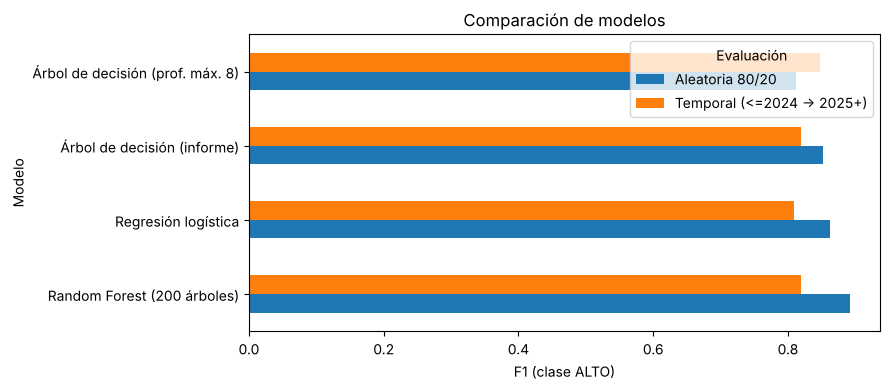

In [12]:
# F1 de la clase ALTO por modelo y tipo de evaluación
tabla.pivot(index='Modelo', columns='Evaluación', values='F1 (ALTO)').round(3).plot.barh(figsize=(9, 4))
import matplotlib.pyplot as plt
plt.xlabel('F1 (clase ALTO)'); plt.title('Comparación de modelos'); plt.tight_layout(); plt.show()

**Lectura:** la clase ALTO es la minoritaria (~7 %), por lo que el F1 de ALTO es más informativo que el accuracy. Si un modelo baja mucho en la evaluación temporal, está memorizando el pasado en lugar de generalizar.

## Sección 10: Visualización del árbol de decisión
Se muestran los primeros 3 niveles (el árbol completo es mucho más profundo).

Profundidad del árbol: 22 | Hojas: 223


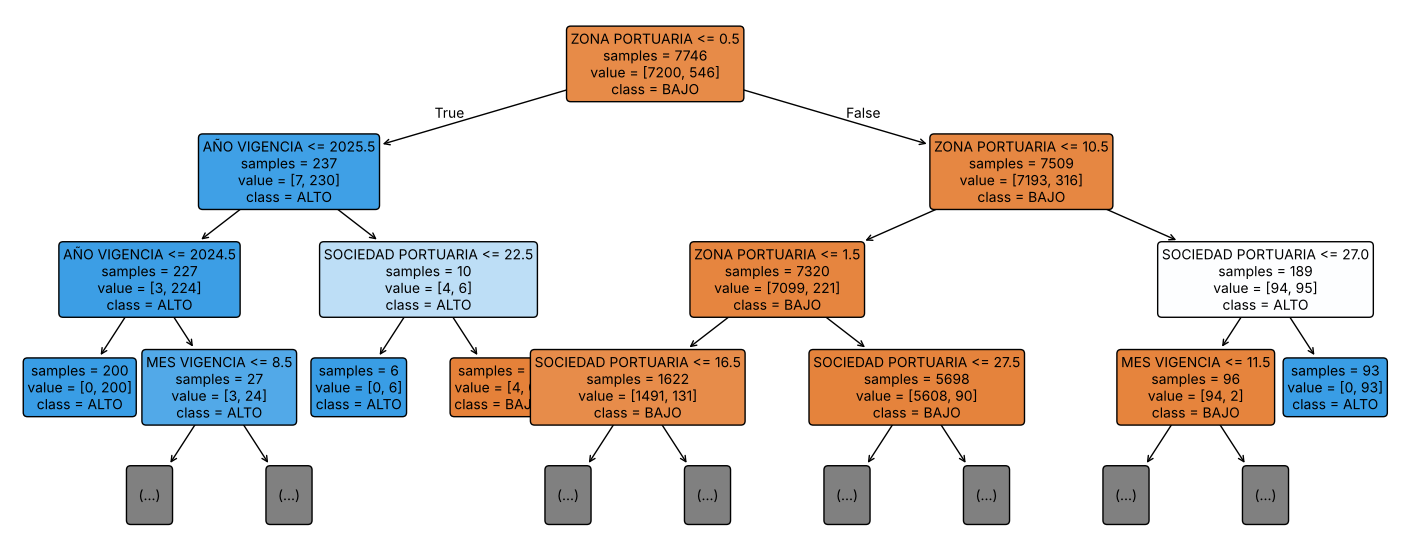

In [13]:
from sklearn.tree import plot_tree, export_text

print(f"Profundidad del árbol: {clf.get_depth()} | Hojas: {clf.get_n_leaves()}")

plt.figure(figsize=(18, 7))
plot_tree(clf, feature_names=features, class_names=['BAJO', 'ALTO'], max_depth=3,
          filled=True, rounded=True, fontsize=10, impurity=False)
plt.show()

In [14]:
# Código numérico que el árbol asigna a cada categoría (para leer 'ZONA PORTUARIA <= 0.5', etc.)
for col, le in label_encoders.items():
    print(col)
    for codigo, categoria in enumerate(le.classes_):
        print(f"   {codigo}: {categoria}")

ZONA PORTUARIA
   0: BARRANCABERMEJA
   1: BARRANQUILLA
   2: BUENAVENTURA
   3: CARTAGENA
   4: CIENAGA
   5: G. MORROSQUILLO
   6: GUAJIRA
   7: SAN ANDRES
   8: SANTA MARTA
   9: TUMACO
   10: TURBO
   11: Z.P. RIO MAGDALENA
SOCIEDAD PORTUARIA
   0: ALGRANEL S.A.
   1: AMERICAN PORT COMPANY INC
   2: ATUNAMAR LIMITADA
   3: BARRANQUILLA INTERNATIONAL TERMINAL COMPANY S.A.
   4: C.I. UNIÓN DE BANANEROS DE URABA S.A. - UNIBAN
   5: CENIT TRANSPORTE Y LOGÍSTICA DE HIDROCARBUROS SAS
   6: CERREJON ZONA NORTE S.A.
   7: COMPAÑIA DE PUERTOS ASOCIADOS S.A.
   8: COREMAR SHOREBASE SA
   9: DELTA SOCIEDAD PORTUARIA S.A.
   10: ECOPETROL S.A.
   11: GRUPO PORTUARIO S.A
   12: NUEVA SOCIEDAD PORTUARIA ZONA ATLANTICA S A
   13: OFICINA DE CONTROL INTERNO DIC
   14: OLEODUCTO CENTRAL S.A.
   15: OTAMERICA COLOMBIA SA
   16: PALERMO SOCIEDAD PORTUARIA S.A
   17: PORTMAGDALENA S.A.
   18: PORTUARIA PUNTA DE VACA S.A.
   19: PRIMAX COLOMBIA S.A
   20: PROMOTORA BANANERA S.A
   21: PUERTO BRISA S.A.